<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_CYS_Projects/blob/main/01-iris-flower-classification/Iris_Flower_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Code Cell 1 — Import libraries

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


###Cell 2 — Load Dataset

In [ ]:

iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = pd.Series(iris.target, name="target")

df = X.copy()
df["target"] = y
df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Features:", iris.feature_names)
print("Classes:", iris.target_names)

df.head()


Dataset loaded successfully!
Dataset shape: (150, 6)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


### Cell 3 — Explore Dataset

In [ ]:

print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df["species"].value_counts())

print("\nStatistical Summary:")
display(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Class Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


### Cell 4 — Visualize Dataset

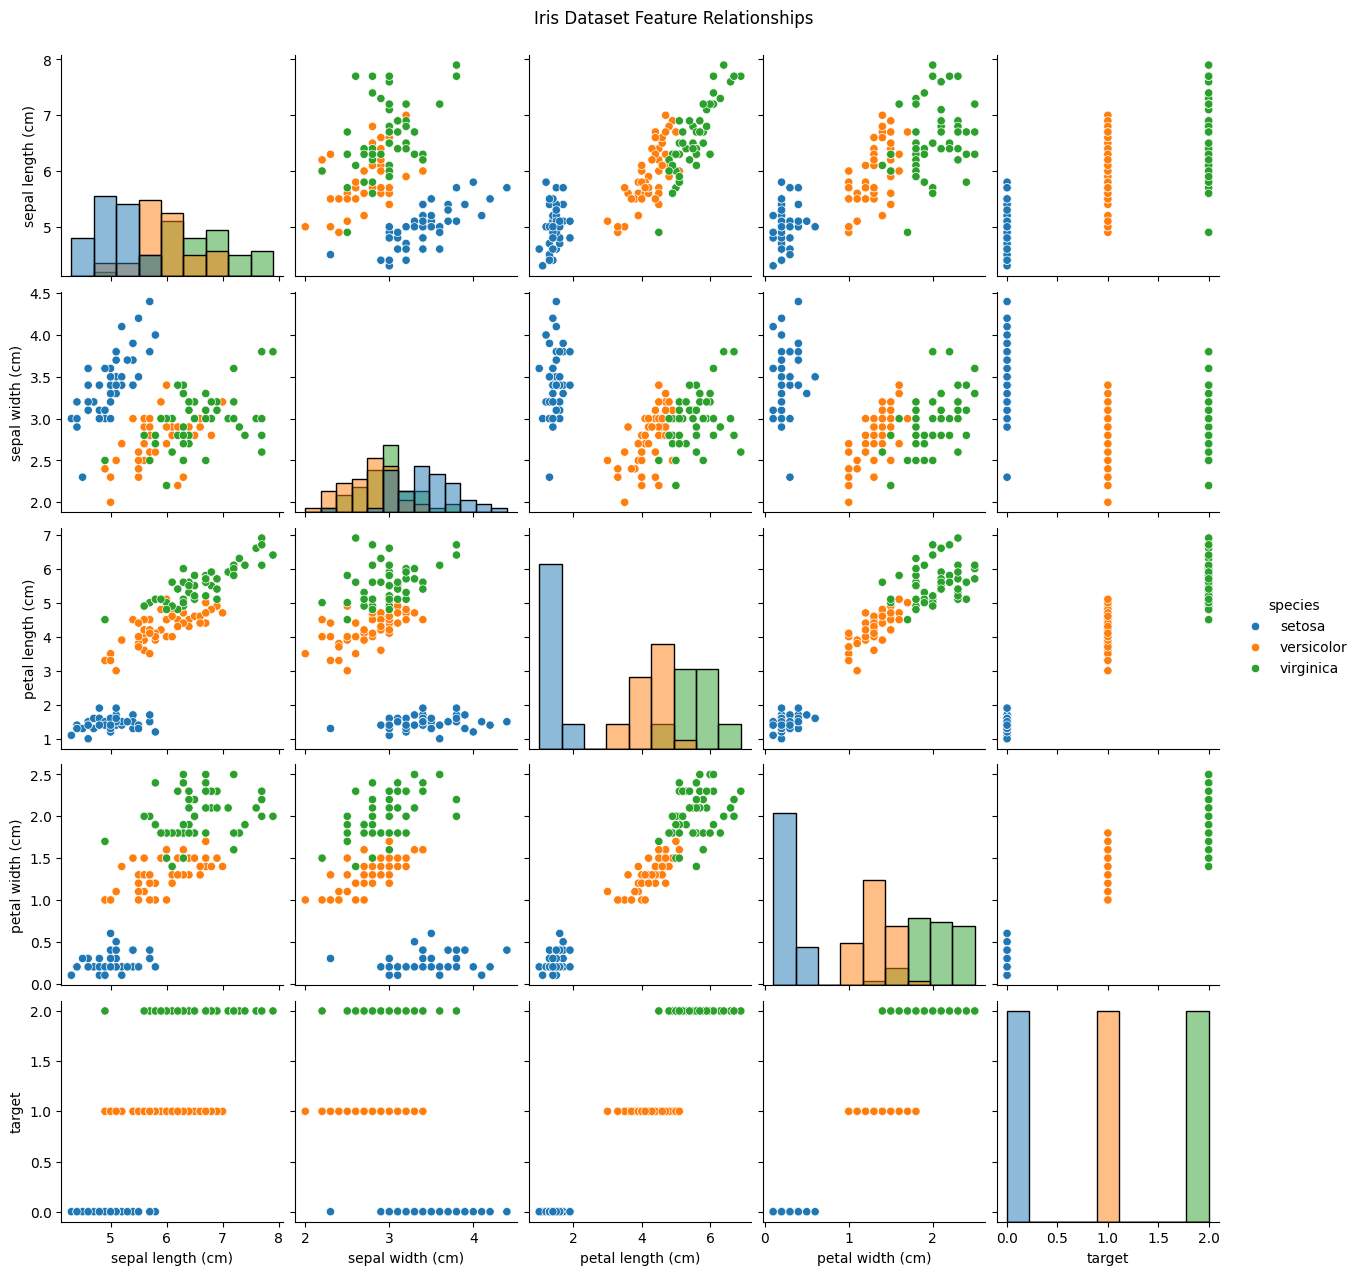

In [ ]:

sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle(
    "Iris Dataset Feature Relationships",
    y=1.02
)

plt.show()


###Cell 5 — Prepare Training and Testing Data

We will use 80% of the data for training and 20% for testing. `stratify=y` will help maintain the proportion of each class.

In [ ]:

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of features:", X_train.shape[1])


Training samples: 120
Testing samples: 30
Number of features: 4


### Cell 6 — Define Four Models

For Logistic Regression and SVM, feature scaling will be performed within the pipeline. Scaling is not mandatory for Decision Tree and Random Forest.

In [ ]:

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf")
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

print("Models ready:")
for name in models:
    print("-", name)


Models ready:
- Logistic Regression
- SVM
- Decision Tree
- Random Forest


### Cell 7 — Train All Models

In [ ]:

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")


Logistic Regression trained successfully.
SVM trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


### Cell 8 — Evaluate Accuracy, Precision, Recall and F1-score

For multiclass classification, the weighted average is used here. This ensures that the number of samples in each class is taken into account when calculating the metrics.

In [ ]:

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1-Score",
        ascending=False
    ).round(4)
)


,Model,Accuracy,Precision,Recall,F1-Score
1,SVM,0.9667,0.9697,0.9667,0.9666
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
2,Decision Tree,0.9333,0.9333,0.9333,0.9333
3,Random Forest,0.9000,0.9024,0.9000,0.8997


### Cell 9 — Compare Model Performance

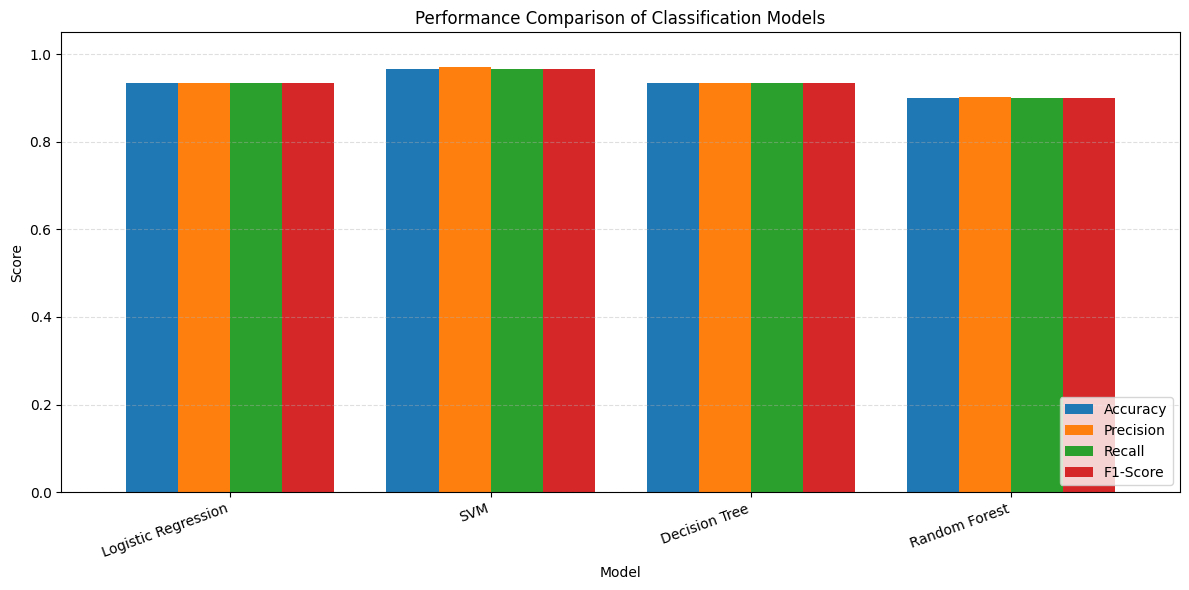

In [ ]:

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05),
    width=0.8
)

plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


### Cell 10 — Classification Reports

In [ ]:

for name, model in models.items():
    y_pred = model.predict(X_test)

    print("=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=iris.target_names,
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

SVM
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90    

### Cell 11 — Confusion Matrices

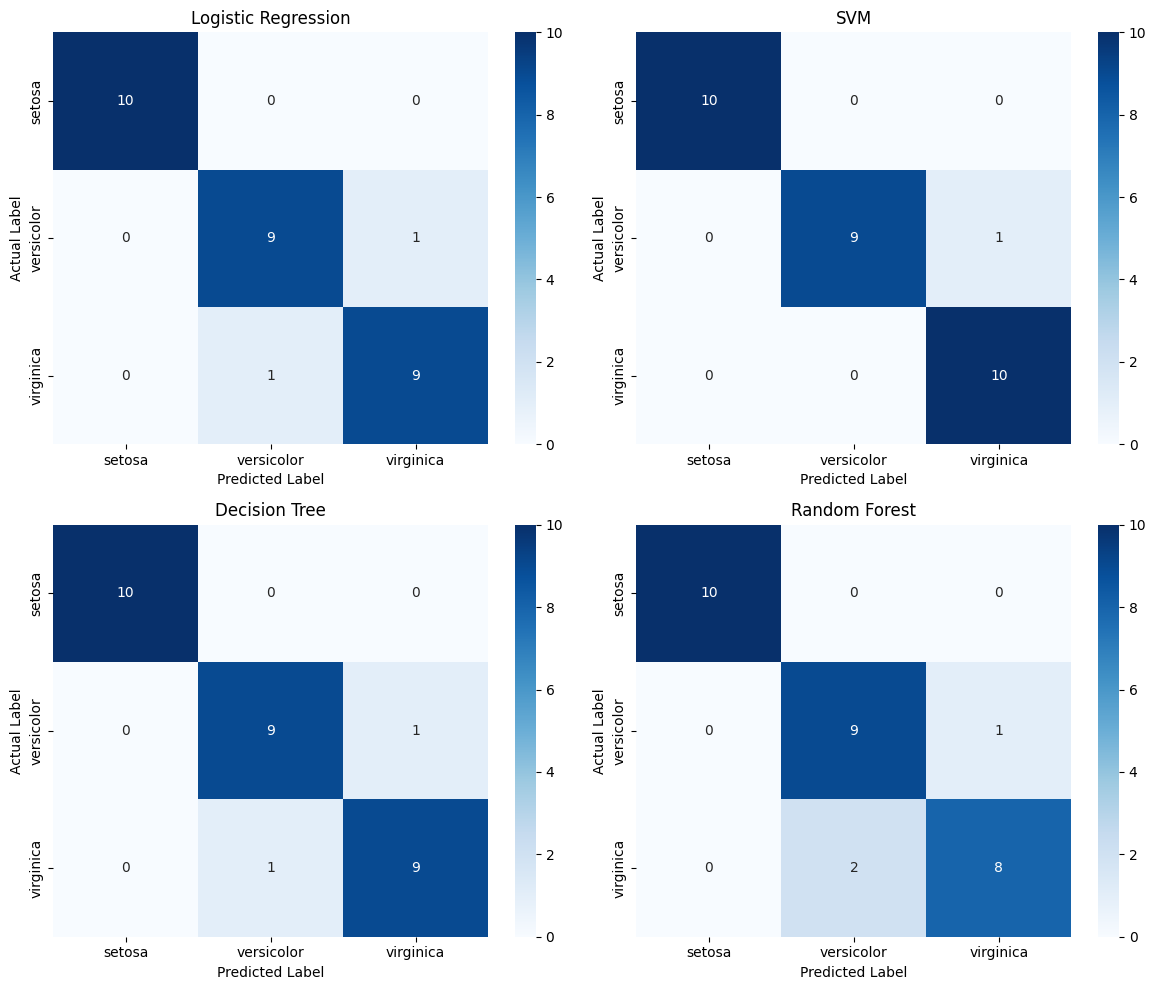

In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, model) in zip(axes.flat, models.items()):
    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1, 2]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


### Cell 12 — Identify the Best Model

In [ ]:

best_row = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("Best Model:", best_row["Model"])
print(f"Accuracy:  {best_row['Accuracy']:.4f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall:    {best_row['Recall']:.4f}")
print(f"F1-Score:  {best_row['F1-Score']:.4f}")


Best Model: SVM
Accuracy:  0.9667
Precision: 0.9697
Recall:    0.9667
F1-Score:  0.9666


### Cell 12 — Identify the Best Model

The model with the highest weighted F1-score is shown here. This result applies only to the specific train-test split and does not prove it is the best model in all situations.

In [ ]:

best_row = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("Best Model:", best_row["Model"])
print(f"Accuracy:  {best_row['Accuracy']:.4f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall:    {best_row['Recall']:.4f}")
print(f"F1-Score:  {best_row['F1-Score']:.4f}")


Best Model: SVM
Accuracy:  0.9667
Precision: 0.9697
Recall:    0.9667
F1-Score:  0.9666


### Cell 13 — Test a New Flower Sample

In the following example, the four input features are ordered as sepal length, sepal width, petal length, and petal width, all measured in centimeters.

In [ ]:

sample = [[5.1, 3.5, 1.4, 0.2]]

print("Sample input:", sample[0])
print()

for name, model in models.items():
    prediction = model.predict(sample)[0]
    predicted_species = iris.target_names[prediction]

    print(f"{name}: {predicted_species}")


Sample input: [5.1, 3.5, 1.4, 0.2]

Logistic Regression: setosa
SVM: setosa
Decision Tree: setosa
Random Forest: setosa


### Cell 14 — Save Results as CSV

In [ ]:

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
)

results_df.to_csv(
    "iris_model_comparison.csv",
    index=False
)

print("Results saved to iris_model_comparison.csv")


Results saved to iris_model_comparison.csv


### Cell 15 — Download Results

In [ ]:

from google.colab import files

files.download("iris_model_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Cell 16 — 5-Fold Cross-Validation

In [ ]:

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision_weighted": "precision_weighted",
    "recall_weighted": "recall_weighted",
    "f1_weighted": "f1_weighted"
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        return_train_score=False
    )

    cv_results.append({
        "Model": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Precision Mean": scores["test_precision_weighted"].mean(),
        "Recall Mean": scores["test_recall_weighted"].mean(),
        "F1 Mean": scores["test_f1_weighted"].mean(),
        "F1 Std": scores["test_f1_weighted"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values(
        by="F1 Mean",
        ascending=False
    ).round(4)
)


,Model,Accuracy Mean,Accuracy Std,Precision Mean,Recall Mean,F1 Mean,F1 Std
1,SVM,0.9600,0.0389,0.9611,0.9600,0.9599,0.0389
0,Logistic Regression,0.9533,0.0452,0.9549,0.9533,0.9532,0.0453
2,Decision Tree,0.9533,0.0340,0.9572,0.9533,0.9531,0.0341
3,Random Forest,0.9467,0.0267,0.9512,0.9467,0.9464,0.0268


### Cell 17: Graph of the Mean F1-Scores of the Four Models

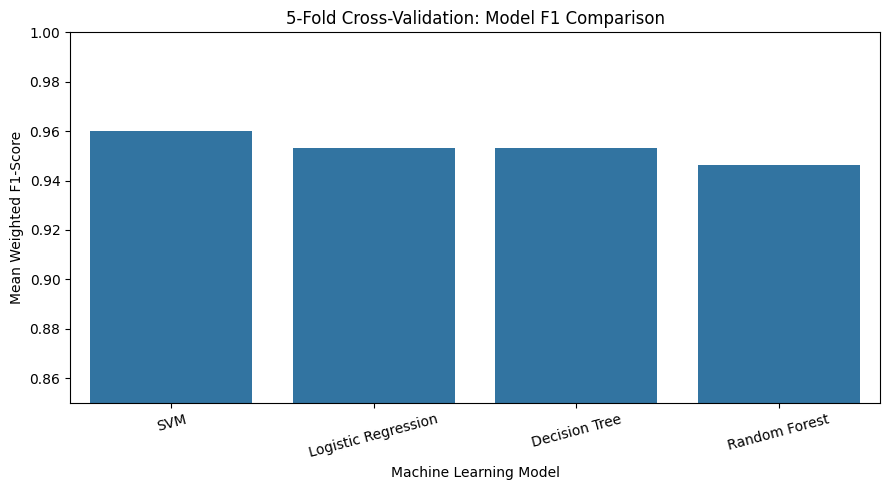

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

cv_plot_df = cv_results_df.sort_values(
    by="F1 Mean",
    ascending=False
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=cv_plot_df,
    x="Model",
    y="F1 Mean"
)

plt.title("5-Fold Cross-Validation: Model F1 Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Mean Weighted F1-Score")
plt.ylim(0.85, 1.00)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### Results Analysis

#### 1. Model Performance

Four machine learning classification models were evaluated: Logistic Regression, Support Vector Machine (SVM), Decision Tree, and Random Forest. Their performance was compared using accuracy, weighted precision, weighted recall, and weighted F1-score.

On the single 80:20 train-test split, SVM achieved the highest accuracy of 96.67% and a weighted F1-score of 96.66%. Logistic Regression and Decision Tree both achieved 93.33% accuracy, while Random Forest achieved 90.00%.

#### 2. Cross-Validation Results

Five-fold stratified cross-validation was used to evaluate model performance across multiple data splits. SVM achieved the highest mean accuracy of 96.00% and the highest mean weighted F1-score of approximately 95.99%. Logistic Regression and Decision Tree achieved mean accuracies of 95.33%, while Random Forest achieved 94.67%.

The cross-validation results support the finding that SVM performed best among the four models in these experiments.

#### 3. Class-Level Performance

All four models correctly classified all Setosa samples in the single test split. Most classification errors occurred between Versicolor and Virginica, which are more difficult to distinguish based on the selected features.

#### 4. Limitations

The Iris dataset is small and contains only three flower classes. The holdout test set contains just 30 samples, so a single incorrect prediction changes accuracy by approximately 3.33 percentage points. Therefore, the results should not be interpreted as evidence that SVM will outperform other models on every dataset.

The cross-validation assessment provides additional evidence, but the evaluation protocol should be carefully documented. For a strictly independent final test, cross-validation should be performed on the training set while keeping the test set untouched.

#### 5. Conclusion

SVM was the best-performing model in this experiment based on both the single test split and the reported five-fold cross-validation results. This project demonstrates a complete introductory machine learning workflow, including data exploration, preprocessing, model training, performance comparison, classification reports, confusion matrices, and cross-validation.